# Batch processing of GRS L2A images with GRSl2bgen

This notebook processes full Sentinel-2 tiles of GRS Level-2A products (Zarr
pyramids) into GRSl2bgen Level-2B water quality products, for one or several tiles
and a date range:

1. **Configuration**: input/output folders, tiles, date range, GRS version, output format.
2. **List the L2A products** found on disk: incomplete products are left out and, when
   a date was processed by several GRS versions, only one is kept.
3. **Output naming**: one L2B product per L2A product, in a `<tile>/YYYY/MM/DD` tree.
4. **Run the batch**: products already processed are skipped, a failing product
   is logged and does not stop the batch, and a summary table is saved.
5. **Quick look** at one L2B product.

For very long batches, the command line is more robust than a notebook: each product
runs in its own Python process, so memory is fully released between products (see the
last section).

```{note}
The outputs shown here come from a short run: tile 31TFJ only (54 L2A products
found) and the dates 2021-02-11 to 2021-02-13, i.e. two full tiles. The timings printed below (about 5 min per tile) were recorded before
the optimisation of GRSl2bgen 1.1.0, which brings a full tile down to about 70 s and 6 GB
of RAM. The notebook is not re-executed when the documentation is built (the data
are not available there); the INFO log of the processing chain is left out.
```

In [1]:
import os
import glob
import time
import shutil
import logging
import warnings
import contextlib
import datetime as dt

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from packaging.version import Version

import GRSl2bgen

opj = os.path.join

# INFO messages of the processing chain; set to logging.WARNING for a quieter batch
logging.getLogger().setLevel(logging.INFO)
# GRS L2A files are stored with chunks that do not match the processing chunks:
# harmless for the results, so the performance hint is silenced
warnings.filterwarnings('ignore', message='The specified chunks separate the stored chunks')

print(f'GRSl2bgen: {GRSl2bgen.__version__}')

GRSl2bgen: 1.1.0dev0


## 1. Configuration

The L2A products are expected in a `<rootdir>/<tile>/YYYY/MM/DD/<product>/` tree, where
`<product>/` is a GRS output directory holding the Zarr pyramid `<product>.zarr` (and
the GRS `log_file.log`). The L2B products are written to the same tree under `<odir>`.

| Parameter | Description |
|---|---|
| `rootdir`, `odir` | root folders of the L2A inputs and of the L2B outputs |
| `tiles` | list of tiles (e.g. `['31TFJ']`), or `None` for all the tiles found in `rootdir` |
| `pattern` | glob pattern of the L2A product names |
| `start_date`, `end_date` | date range to process (inclusive) |
| `version` | GRS version to process (e.g. `'V3.1.0'`), or `None` to keep, for each date, the highest version found |
| `level` | pyramid level read from the L2A: `0` is the full resolution (20 m, 5490 x 5490 px), level `k` is `2**k` coarser |
| `out_ext` | `'.nc'` (NetCDF) or `'.zarr'` (Zarr store) |
| `pyramid` | for `.zarr`: write a multiscale (pyramid) store for cloud visualisation |
| `overwrite` | reprocess products whose L2B output already exists |
| `n_workers` | `None`: dask threaded scheduler; an integer: one local dask cluster with this many worker processes, shared by the whole batch |
| `persist_input` | keep each masked L2A raster in memory (faster, needs more RAM: several GB for a full tile) |

In [2]:
rootdir = '/data/satellite/Sentinel-2/L2A_zarr'
odir = '/data/satellite/Sentinel-2/L2B'

tiles = ['31TFJ']      # None: all the tiles of rootdir; or e.g. ['31TFJ', '31TEJ']
pattern = '*L2A*'
start_date, end_date = '2021-02-11', '2021-02-13'   # e.g. '2021-01-01', '2025-12-31'
version = 'V3.1.0'     # None: highest GRS version of each date
level = 0              # 0: full resolution

out_ext = '.nc'        # '.nc' or '.zarr'
pyramid = False        # only for '.zarr'
overwrite = False

n_workers = None       # e.g. 4
persist_input = False

## 2. List the L2A products

The product names follow the Sentinel-2 convention, followed by the GRS version:

`<satellite>_<level>_<sensing time>_<baseline>_<orbit>_<tile>_<processing time>_<version>`

e.g. `S2A_MSIL2AGRS_20210820T104021_N0500_R008_T31TFJ_20230122T133008_V3.1.0`. The
products are indexed by sensing time, so that a date range can be selected with `.loc`.

A product is **complete** when its Zarr pyramid holds the root metadata and every level
listed in it. Products still being written, or left over by a failed GRS run, are
reported and skipped.

In [3]:
FIELDS = ['satellite', 'level', 'time', 'baseline', 'orbit', 'tile', 'processing_time', 'version']


def product_name(path):
    """Product name without folder and extension."""
    name = os.path.basename(path.rstrip('/'))
    for ext in ('.nc', '.zarr'):
        if name.endswith(ext):
            name = name[:-len(ext)]
    return name


def zarr_store(path):
    """Zarr store of a product: the path itself or <path>/<name>.zarr."""
    path = path.rstrip('/')
    return path if path.endswith('.zarr') else opj(path, product_name(path) + '.zarr')


def is_complete(path):
    """True if the Zarr pyramid of `path` has its root metadata and all its levels."""
    store = zarr_store(path)
    if not os.path.isfile(opj(store, 'zarr.json')):
        return False
    try:
        with xr.open_zarr(store) as root:
            layout = root.attrs.get('multiscales', [{}])[0].get('layout', [])
    except Exception:
        return False
    return all(os.path.isfile(opj(store, lev['group'], 'zarr.json')) for lev in layout)


def list_products(rootdir, tiles=None, pattern='*L2A*'):
    """Table of the L2A products found in <rootdir>/<tile>/YYYY/MM/DD/, indexed by sensing time."""
    if tiles is None:
        tiles = sorted(d for d in os.listdir(rootdir) if os.path.isdir(opj(rootdir, d)))
    paths = sorted(p for tile in tiles
                   for p in glob.glob(opj(rootdir, tile, '*', '*', '*', pattern)))
    rows = []
    for path in paths:
        fields = product_name(path).split('_')
        if len(fields) < 7:
            logging.warning(f'unexpected product name, skipped: {path}')
            continue
        # the version field is optional
        fields = (fields + [None])[:len(FIELDS)]
        rows.append(dict(zip(FIELDS, fields), path=path))
    df = pd.DataFrame(rows, columns=FIELDS + ['path'])
    df['tile'] = df['tile'].str.lstrip('T')
    df['time'] = pd.to_datetime(df['time'], format='%Y%m%dT%H%M%S')
    return df.set_index('time').sort_index()


products = list_products(rootdir, tiles, pattern)
print(f'{len(products)} L2A products found in {rootdir}')
products.groupby(['tile', 'version']).size().rename('products').to_frame().T

54 L2A products found in /data/satellite/Sentinel-2/L2A_zarr


tile,31TFJ
version,V3.1.0
products,54


In [4]:
products['complete'] = products['path'].map(is_complete)
incomplete = products[~products['complete']]
if len(incomplete):
    print(f'{len(incomplete)} incomplete products skipped:')
    print('\n'.join(incomplete['path']))
products = products[products['complete']]

# one GRS version per L1C product: the requested version, or the highest one
# (packaging order: V3.1.0dev0 < V3.1.0)
L1C_KEY = ['tile', 'time', 'processing_time']
if version is not None:
    products = products[products['version'] == version]
else:
    order = products['version'].fillna('0').map(lambda v: Version(v.lstrip('Vv')))
    products = (products.assign(_order=order).sort_values('_order')
                .reset_index()
                .drop_duplicates(L1C_KEY, keep='last')
                .drop(columns='_order')
                .set_index('time').sort_index())

# same sensing time, different ESA processing times: distinct L1C products, both processed
twins = products[products.reset_index().duplicated(['tile', 'time'], keep=False).values]
if len(twins):
    print(f'{len(twins)} products share their tile and sensing time with another one '
          '(different L1C processing times), all are processed:')
    print('\n'.join(twins['path'].map(os.path.basename)))

selection = products.loc[start_date:end_date]
print(f'{len(selection)} products between {start_date} and {end_date}')
selection.groupby(['tile', selection.index.year]).size().rename('products').unstack(fill_value=0)

2 products between 2021-02-11 and 2021-02-13


time,2021
tile,
31TFJ,2


## 3. Output naming

Each L2B product is named as by the `GRSl2bgen` command line
(`GRSl2bgen.run.default_output_name`): the name of its L2A product, with `L2AGRS` (any
case) replaced by `L2B`, e.g.
`S2A_MSIL2B_20210820T104021_N0500_R008_T31TFJ_20230122T133008_V3.1.0`, and is written to
`<odir>/<tile>/YYYY/MM/DD/`.

In [5]:
from GRSl2bgen.run import default_output_name


def l2b_path(l2a_path, tile, sensing_time):
    name = default_output_name(l2a_path)[:-len('.nc')]
    return opj(odir, tile, sensing_time.strftime('%Y/%m/%d'), name + out_ext)


selection = selection.assign(l2b=[l2b_path(row['path'], row['tile'], t)
                                  for t, row in selection.iterrows()])
selection['done'] = selection['l2b'].map(os.path.exists)
print(f"{selection['done'].sum()} already processed, {(~selection['done']).sum()} to process")
selection[['tile', 'path', 'l2b', 'done']].head()

0 already processed, 2 to process


,tile,path,l2b,done
time,,,,
2021-02-11 10:41:51,31TFJ,/data/satellite/Sentinel-2/L2A_zarr/31TFJ/2021...,/data/satellite/Sentinel-2/L2B/31TFJ/2021/02/1...,False
2021-02-13 10:30:39,31TFJ,/data/satellite/Sentinel-2/L2A_zarr/31TFJ/2021...,/data/satellite/Sentinel-2/L2B/31TFJ/2021/02/1...,False


## 4. Run the batch

For each product:

- it is **skipped** if its L2B output already exists (unless `overwrite=True`), so the
  batch can be interrupted and restarted at any time;
- `Process.run` executes the processing chain on pyramid level `level`, writes the
  output and closes the input files;
- if the processing **fails**, the error is logged, the partially written output (if any) is
  removed so that the product is retried at the next run, and the batch goes on.

With `n_workers` set, a single local dask cluster is started for the whole batch
(instead of one per product) and closed at the end. The INFO log of each product is
long for a batch: set the logging level to `logging.WARNING` in the first cell to keep
only the progress lines.

In [6]:
def remove_output(path):
    if os.path.isdir(path):
        shutil.rmtree(path)
    elif os.path.isfile(path):
        os.remove(path)


def process_product(l2a, l2b):
    """Process one product; return (status, duration in s, error message)."""
    if os.path.exists(l2b):
        if not overwrite:
            return 'skipped', 0., ''
        remove_output(l2b)
    os.makedirs(os.path.dirname(l2b), exist_ok=True)
    t0 = time.perf_counter()
    try:
        process = GRSl2bgen.Process(l2a, l2b, pyramid=pyramid, persist_input=persist_input,
                                    level=level)
        process.run()
        del process
        return 'done', time.perf_counter() - t0, ''
    except Exception as e:
        logging.exception(f'processing failed: {l2a}')
        remove_output(l2b)
        return 'failed', time.perf_counter() - t0, f'{type(e).__name__}: {e}'


if n_workers:
    from dask.distributed import Client
    # the client owns the cluster: both are closed at the end of the with block
    scheduler = Client(n_workers=n_workers, threads_per_worker=1)
    print(f'dask dashboard: {scheduler.dashboard_link}')
else:
    scheduler = contextlib.nullcontext()

records = []
with scheduler:
    for i, (sensing_time, row) in enumerate(selection.iterrows(), start=1):
        status, duration, error = process_product(row['path'], row['l2b'])
        records.append(dict(time=sensing_time, tile=row['tile'], status=status,
                            duration_s=round(duration, 1), error=error,
                            l2a=row['path'], l2b=row['l2b']))
        if status != 'skipped':
            print(f'[{i}/{len(selection)}] {status:6s} {os.path.basename(row["l2b"])} ({duration:.1f} s)')

summary = pd.DataFrame(records, columns=['time', 'tile', 'status', 'duration_s', 'error',
                                         'l2a', 'l2b'])
summary['status'].value_counts()

[1/2] done   S2A_MSIL2B_20210211T104151_N0500_R008_T31TFJ_20230608T124831_V3.1.0.nc (317.5 s)
[2/2] done   S2B_MSIL2B_20210213T103039_N0500_R108_T31TFJ_20230609T061428_V3.1.0.nc (309.3 s)


status
done    2
Name: count, dtype: int64

The summary is saved as a CSV file in `odir`. Failed products can be inspected below and
reprocessed by running the batch again.

In [7]:
if len(summary):
    log_file = opj(odir, f'l2bgen_batch_{dt.datetime.now():%Y%m%dT%H%M%S}.csv')
    os.makedirs(os.path.dirname(log_file), exist_ok=True)
    summary.to_csv(log_file, index=False)
    print(f'summary saved to {log_file}')
    processed = summary[summary.status == 'done']
    if len(processed):
        print(f'mean processing time: {processed.duration_s.mean():.1f} s per product')

summary[summary.status == 'failed'][['time', 'tile', 'error', 'l2a']]

summary saved to /data/satellite/Sentinel-2/L2B/l2bgen_batch_20261019T182141.csv
mean processing time: 313.4 s per product


,time,tile,error,l2a


## 5. Quick look at one L2B product

The last processed product of the selection is displayed. A full tile is large for a
figure, so one pixel out of `step` is shown. A pyramid Zarr store holds one group per
resolution level: a coarse level is read directly instead.

In [8]:
done = selection[selection['l2b'].map(os.path.exists)]
l2b_file = done['l2b'].iloc[-1]
step = 4                            # 1 pixel out of `step` in x and y (80 m for a 20 m tile)
if l2b_file.endswith('.zarr') and pyramid:
    l2b = xr.open_zarr(l2b_file, group='2', decode_coords='all')    # 2**2 coarser
    step = 1
elif l2b_file.endswith('.zarr'):
    l2b = xr.open_zarr(l2b_file, decode_coords='all')
else:
    l2b = xr.open_dataset(l2b_file, decode_coords='all')
l2b = l2b.isel(x=slice(None, None, step), y=slice(None, None, step))
l2b

<xarray.Dataset> Size: 394MB
Dimensions:                    (Nclasses: 3, y: 1373, x: 1373)
Coordinates:
  * Nclasses                   (Nclasses) int64 24B 0 1 2
  * y                          (y) float64 11kB 4.9e+06 4.9e+06 ... 4.79e+06
  * x                          (x) float64 11kB 6e+05 6.001e+05 ... 7.098e+05
    band                       int64 8B ...
    spatial_ref                int32 4B ...
    time                       datetime64[ns] 8B ...
    central_wavelength         float32 4B ...
    wl                         int64 8B ...
Data variables: (12/24)
    owt_dist_Spyrakos2018      (Nclasses, y, x) float64 45MB ...
    owt_index_Spyrakos2018     (Nclasses, y, x) float32 23MB ...
    owt_dist_Bi2024            (y, x) float64 15MB ...
    owt_index_Bi2024           (y, x) float32 8MB ...
    owt_dist_Ta2025            (y, x) float64 15MB ...
    owt_index_Ta2025           (y, x) float32 8MB ...
    ...                         ...
    adg443_QAAv6Chl            (y, x) float64 15MB ...
    Kd_par                     (y, x) float64 15MB ...
    Zsd_Lee15                  (y, x) float64 15MB ...
    flags                      (y, x) uint32 8MB ...
    flags_l2b                  (y, x) uint32 8MB ...
    mask                       (y, x) uint8 2MB ...
Attributes: (12/77)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2B_MSIL1C_20210213T103039_N0500_R10...
    instrument:                          MSI
    ...                                  ...
    hcld_threshold:                      0.003
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    GRSdriver_version:                   2.0.4
    metadata_profile:                    datacube

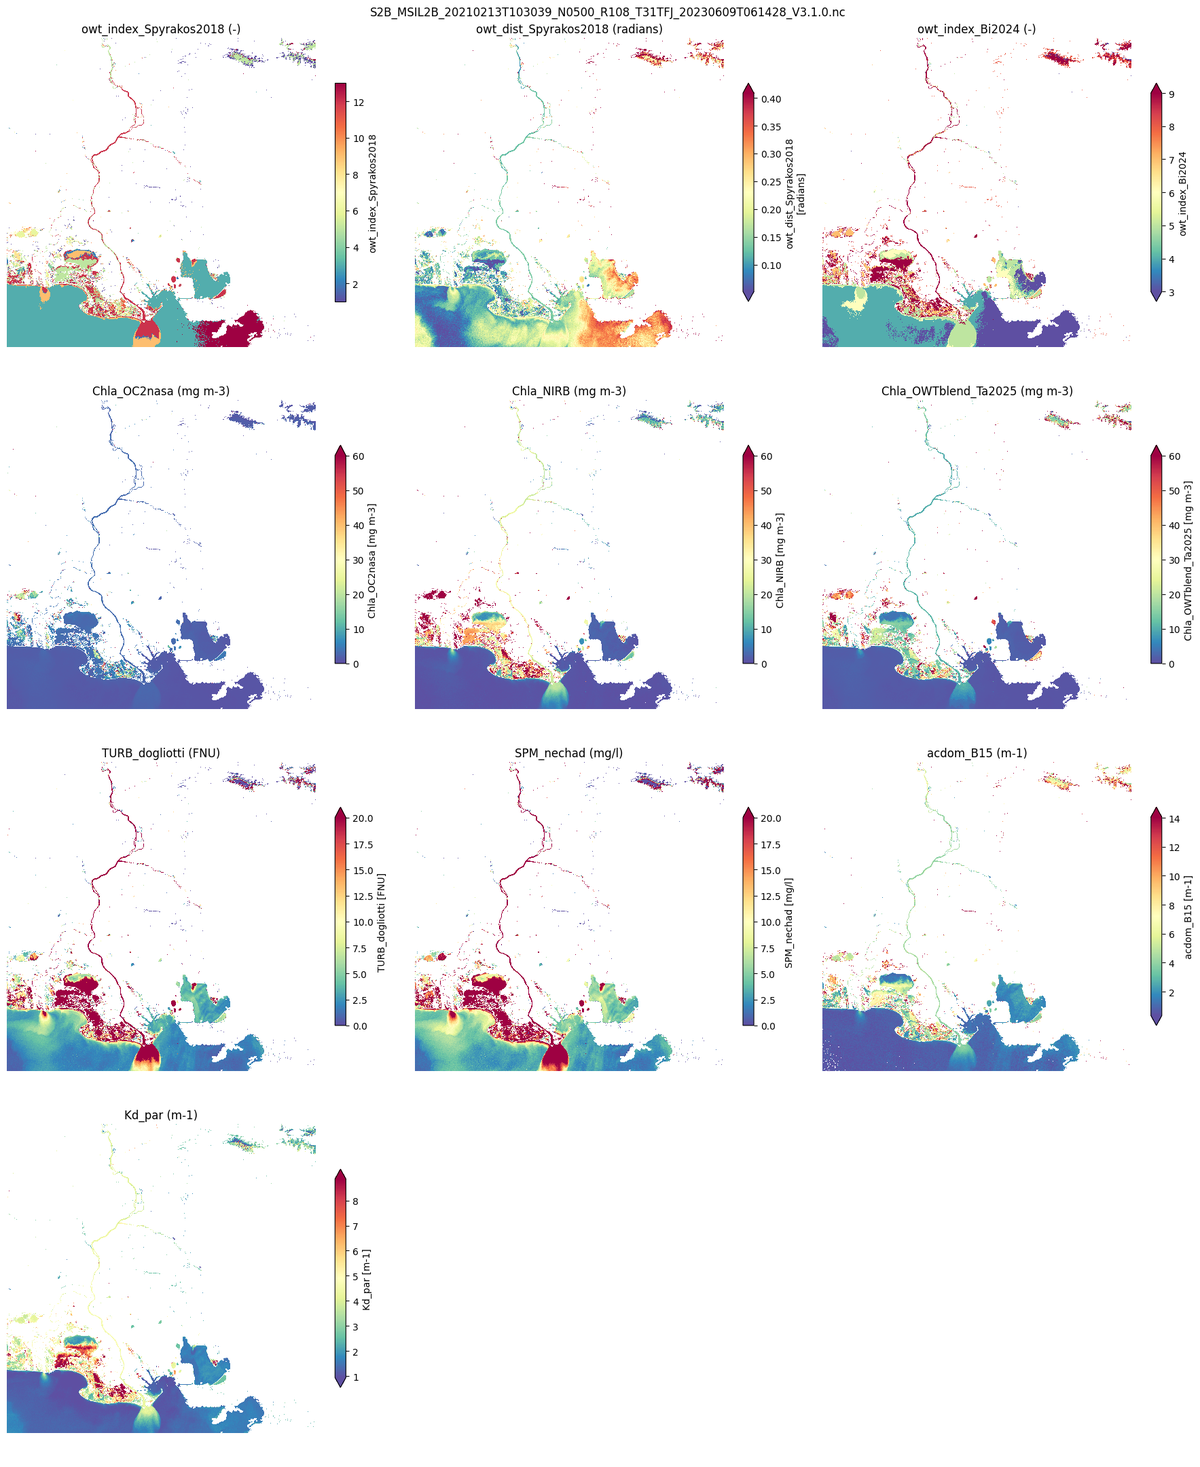

In [9]:
params = ['owt_index_Spyrakos2018', 'owt_dist_Spyrakos2018', 'owt_index_Bi2024',
          'Chla_OC2nasa', 'Chla_NIRB', 'Chla_OWTblend_Ta2025',
          'TURB_dogliotti', 'SPM_nechad', 'acdom_B15', 'Kd_par']
params = [p for p in params if p in l2b]
vmax = {'Chl': 60, 'TURB': 20, 'SPM': 20}   # colour scale upper limits by parameter family

# UTM projection from the EPSG code (326zz: north, 327zz: south)
epsg = l2b.rio.crs.to_epsg()
proj = ccrs.UTM(epsg % 100, southern_hemisphere=(epsg // 100 == 327))

ncols = 3
nrows = int(np.ceil(len(params) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.5 * nrows),
                        subplot_kw={'projection': proj})
for ax in axs.ravel():
    ax.set_axis_off()
for ax, param in zip(axs.ravel(), params):
    da = l2b[param]
    if 'Nclasses' in da.dims:          # 3 best Spyrakos classes: show the first one
        da = da.isel(Nclasses=0)
    family = next((k for k in vmax if param.startswith(k)), None)
    kwargs = dict(vmin=0, vmax=vmax[family]) if family else {}
    da.squeeze().plot.imshow(ax=ax, cmap=plt.cm.Spectral_r, robust=True,
                             cbar_kwargs={'shrink': 0.6}, **kwargs)
    ax.set_title(f"{param} ({da.attrs.get('units', '-')})")
fig.suptitle(os.path.basename(l2b_file))
plt.tight_layout()

## Alternative: batch from the command line

For long batches, run one `GRSl2bgen` process per product from a shell script:
memory is fully released after each product. A full tile takes about 70 s and
6 GB of RAM (default of 8 threads), i.e. about 2 hours for 100 products. Products
can be processed in parallel with `xargs -P`: two at a time take about 90 s each
(about 45 s per product overall) but need twice the memory, so keep the number of
parallel products well within the free RAM. Products already processed are skipped,
and the date range is selected on the `YYYY/MM/DD` folders. The log of each product is
written next to it, as `<name>.log`, with its peak memory and run time at the end.

```bash
rootdir=/data/satellite/Sentinel-2/L2A_zarr
odir=/data/satellite/Sentinel-2/L2B
start=2021-01-01 end=2025-12-31
version=V3.1.0

process_one() {
    rel=${1#$rootdir/}                               # <tile>/YYYY/MM/DD/<product>
    name=$(basename "$1")
    out="$odir/$(dirname "$rel")/${name/L2AGRS/L2B}.nc"
    [ -e "$out" ] && return                          # already processed
    [ -f "$1/$name.zarr/zarr.json" ] || { echo "INCOMPLETE $1" >> "$odir/failed.txt"; return; }
    GRSl2bgen "$1" -o "$out" || echo "FAILED $1" >> "$odir/failed.txt"
}
export -f process_one; export rootdir odir

# products of the date range and version, one at a time (-P 2: two in parallel)
find "$rootdir" -mindepth 5 -maxdepth 5 -type d -name "*L2A*_$version" | sort |
    awk -v s="$start" -v e="$end" -F/ '{d=$(NF-3)"-"$(NF-2)"-"$(NF-1)} d>=s && d<=e' |
    xargs -P 1 -I{} bash -c 'process_one {}'
```